# COMP4318/5318 Assignment 2: Image Classification

Course-provided PathMNIST subset. This notebook follows the template's five sections.
Run from the `a2` directory in order. Search cells in Section 3 may be skipped on a later rerun;
Section 4 uses fixed selected settings and does not read search results.

### Group number: 64  , SID1: 540935875 , SID2: 550087894, SID3: 520271713, SID4: 510469531

The input files are the four provided `.npy` arrays in `Assignment2Data`.
All model selection uses a stratified validation split of the supplied training set.
Test labels are inspected here for descriptive class counts only; no test-set
prediction score informs model selection.
Class IDs 0–8 are used because the course arrays do not include a class-name mapping.

## Setup and dependencies

Python 3.12; NumPy 1.26.4, scikit-learn 1.8.0, pandas 3.0.2, Matplotlib 3.10.8,
Keras 3.15.1 with the already available PyTorch 2.11.0 backend.
The MAS conda environment already contained everything except Keras and five direct
dependencies. Those six packages were placed in this project's `.deps` directory;
no system or conda default paths or installed packages were changed.
If `.deps` is absent on another computer, install `keras==3.15.1` and a Keras
backend in that Python environment (for example, `torch==2.11.0`). The notebook
defaults to torch *for this process* before importing Keras; a different
KERAS_BACKEND environment variable may be set before starting the kernel.
All main models use scikit-learn or Keras APIs; there are no pretrained networks.

In [1]:
import os
import sys
import time
from pathlib import Path

# Keras requires backend selection before its first import. This process-local
# setting does not alter any user/system defaults.
os.environ.setdefault("KERAS_BACKEND", "torch")
LOCAL_DEPS = Path(".deps")
if LOCAL_DEPS.is_dir():
    sys.path.insert(0, str(LOCAL_DEPS.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, ParameterGrid
import sklearn
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
print("Keras:", keras.__version__, "backend:", keras.backend.backend())

Python: 3.12.13
NumPy: 1.26.4 scikit-learn: 1.8.0
Keras: 3.15.1 backend: torch


## Data loading, exploration, and preprocessing

Read the course's own arrays, retaining its training/test split. We do not
download the original MedMNIST split. Check shapes, pixel values, class counts
and representative images before choosing transformations.

In [2]:
# Code supplied in the template; execute with the working directory set to a2.
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

assert X_train.ndim == X_test.ndim == 4
assert X_train.shape[1:] == X_test.shape[1:] == (28, 28, 3)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert X_train.dtype == X_test.dtype == np.uint8
assert set(np.unique(y_train)) == set(np.unique(y_test))
NUM_CLASSES = len(np.unique(y_train))
print("Training images/labels:", X_train.shape, y_train.shape)
print("Test images/labels:", X_test.shape, y_test.shape)
print("Classes:", NUM_CLASSES, "pixel range:", int(X_train.min()), int(X_train.max()))

Training images/labels: (32000, 28, 28, 3) (32000,)
Test images/labels: (8000, 28, 28, 3) (8000,)
Classes: 9 pixel range: 0 255


 class_id  train_count train_pct  test_count
        0         3490     10.91         873
        1         3431     10.72         858
        2         3505     10.95         877
        3         3656     11.43         914
        4         2950      9.22         737
        5         4290     13.41        1072
        6         2728      8.53         682
        7         3253     10.17         813
        8         4697     14.68        1174
Majority-class baseline: 0.1468
RGB train mean: [188.65 135.93 180.05]
RGB train std: [31.91 45.6  32.18]


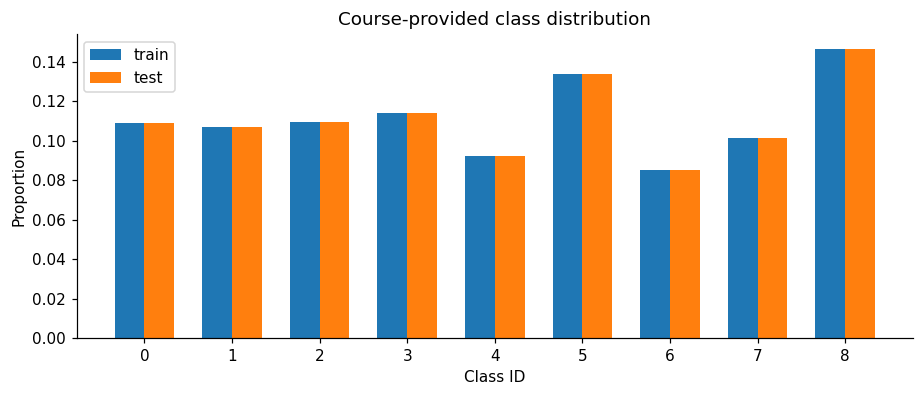

In [3]:
class_ids, train_counts = np.unique(y_train, return_counts=True)
_, test_counts = np.unique(y_test, return_counts=True)
class_table = pd.DataFrame({
    "class_id": class_ids,
    "train_count": train_counts,
    "train_pct": 100 * train_counts / len(y_train),
    "test_count": test_counts,
})
print(class_table.to_string(index=False, formatters={"train_pct": "{:.2f}".format}))
print("Majority-class baseline:", f"{train_counts.max()/len(y_train):.4f}")
print("RGB train mean:", np.round(X_train.mean(axis=(0, 1, 2)), 2))
print("RGB train std:", np.round(X_train.std(axis=(0, 1, 2)), 2))

fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.bar(class_ids - .17, train_counts / len(y_train), width=.34, label="train")
ax.bar(class_ids + .17, test_counts / len(y_test), width=.34, label="test")
ax.set(xticks=class_ids, xlabel="Class ID", ylabel="Proportion", title="Course-provided class distribution")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "class_balance.png", dpi=180)
plt.show()

### Examples of preprocessed data

The original pixels are unsigned integers in `[0,255]`. Divide by 255 into
`float32` values in `[0,1]` for the neural networks. The 9-class labels remain
integer IDs. For the random forest, use RGB 2×2 mean pooling plus colour
variation and adjacent-pixel difference summaries. This keeps coarse spatial
layout and some texture while reducing the raw 2352 pixels to 597 features.
These are deterministic per-image operations and learn no statistics from the
validation or test samples. An 80/20 stratified validation split is made
*only from the supplied training set* (25,600/6,400 images).

In [4]:
y_train = y_train.astype(np.int64, copy=False)
y_test = y_test.astype(np.int64, copy=False)
X_train_img = X_train.astype(np.float32) / 255.0
X_test_img = X_test.astype(np.float32) / 255.0


def extract_rf_features(images, batch_size=1024):
    '''14x14x3 RGB spatial means + RGB std + horizontal/vertical roughness.'''
    output = np.empty((len(images), 597), dtype=np.float32)
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        batch = images[start:stop]
        pooled = batch.reshape(-1, 14, 2, 14, 2, 3).mean(axis=(2, 4)).reshape(-1, 588)
        rgb_std = batch.std(axis=(1, 2))
        horizontal = np.abs(np.diff(batch, axis=2)).mean(axis=(1, 2))
        vertical = np.abs(np.diff(batch, axis=1)).mean(axis=(1, 2))
        output[start:stop] = np.concatenate((pooled, rgb_std, horizontal, vertical), axis=1)
    return output


X_train_rf = extract_rf_features(X_train_img)
X_test_rf = extract_rf_features(X_test_img)
dev_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=.20, stratify=y_train, random_state=SEED,
)
X_dev_img, X_val_img = X_train_img[dev_idx], X_train_img[val_idx]
y_dev, y_val = y_train[dev_idx], y_train[val_idx]
X_dev_rf, X_val_rf = X_train_rf[dev_idx], X_train_rf[val_idx]
assert not set(dev_idx) & set(val_idx)
assert X_train_rf.shape[1] == 597
print("Neural input:", X_train_img.shape[1:], "range:", (X_train_img.min(), X_train_img.max()))
print("RF input dimension:", X_train_rf.shape[1])
print("Development/validation:", len(dev_idx), len(val_idx))
print("Validation class counts:", np.bincount(y_val, minlength=NUM_CLASSES))

Neural input: (28, 28, 3) range: (0.0, 1.0)
RF input dimension: 597
Development/validation: 25600 6400
Validation class counts: [698 686 701 731 590 858 546 651 939]


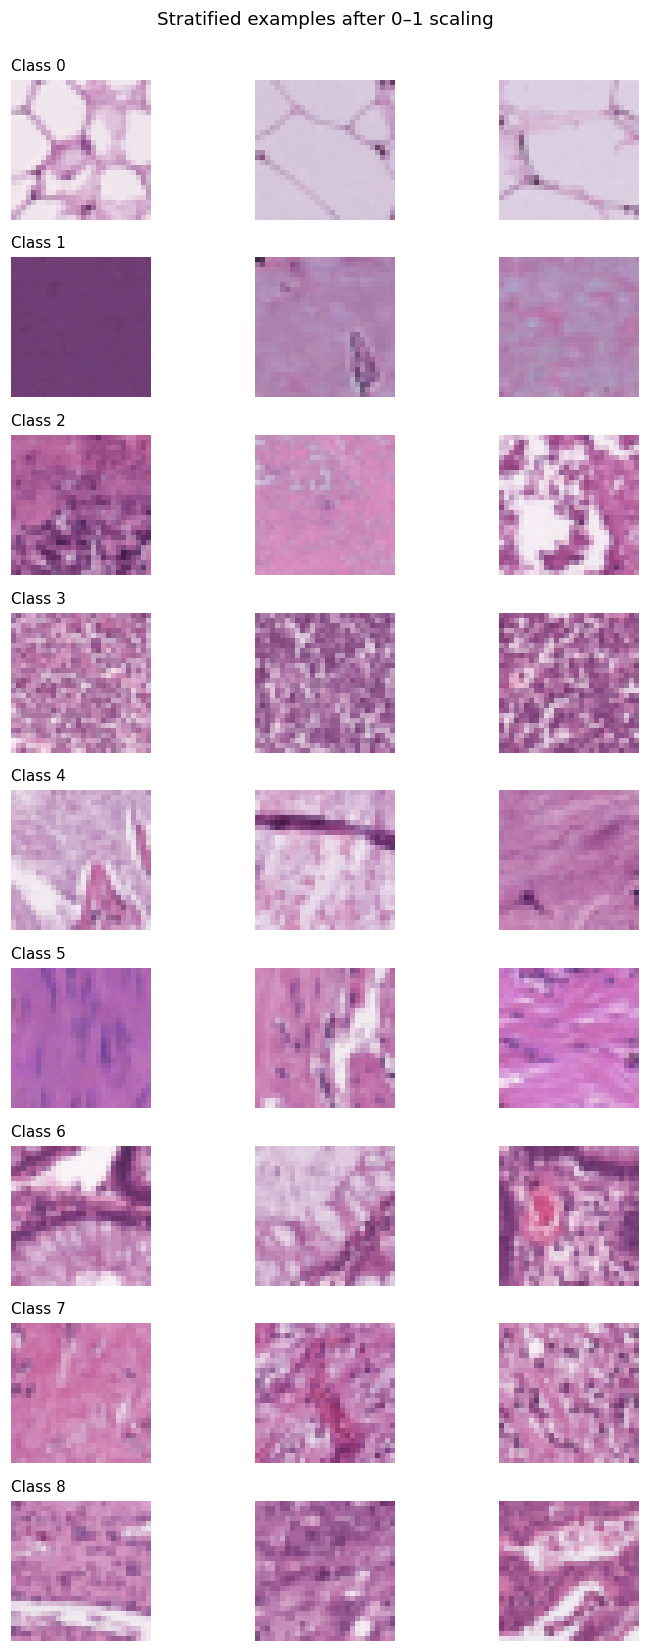

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(7.4, 15))
for class_id in range(NUM_CLASSES):
    examples = rng.choice(np.flatnonzero(y_train == class_id), size=3, replace=False)
    for column, sample_index in enumerate(examples):
        axes[class_id, column].imshow(X_train_img[sample_index])
        axes[class_id, column].axis("off")
        if column == 0:
            axes[class_id, column].set_title(f"Class {class_id}", loc="left", fontsize=10)
fig.suptitle("Stratified examples after 0–1 scaling", y=.998)
fig.tight_layout()
fig.savefig(FIGURES / "preprocessed_examples.png", dpi=160)
plt.show()

## Algorithm design and setup

### Algorithm of choice from first six weeks of course: Random Forest

The classical baseline is a random forest. Its trees split on pooled colour
and roughness features; bootstrap samples and random feature subsets reduce
similarity among trees. It needs no global normalisation fitted on the test set.
The small initial instance below is trained and evaluated **before** tuning.

In [6]:
def evaluate_labels(true, predicted):
    return {
        "accuracy": float(accuracy_score(true, predicted)),
        "macro_f1": float(f1_score(true, predicted, average="macro", zero_division=0)),
    }


rf_initial = RandomForestClassifier(
    n_estimators=60, max_depth=14, random_state=SEED, n_jobs=4,
)
t0 = time.perf_counter()
rf_initial.fit(X_dev_rf, y_dev)
rf_initial_seconds = time.perf_counter() - t0
rf_initial_metrics = evaluate_labels(y_val, rf_initial.predict(X_val_rf))
print("Initial RF:", rf_initial_metrics, "fit seconds:", f"{rf_initial_seconds:.2f}")

Initial RF: {'accuracy': 0.7046875, 'macro_f1': 0.6869785523436184} fit seconds: 3.61


### Fully connected neural network

Flatten all 28×28×3 pixels, then use two learned Dense layers with batch
normalisation, ReLU, dropout and a 9-way softmax. This can learn feature interactions, but flattening
discards explicit neighbourhood structure and increases the first layer's
parameter count. The initial instance is evaluated here, before tuning.

In [7]:
def build_mlp(hidden_units=256, dropout=.10, learning_rate=.0005):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 3)),
        layers.Flatten(),
        layers.Dense(hidden_units, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(hidden_units // 2, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
mlp_initial = build_mlp()
t0 = time.perf_counter()
mlp_initial_history = mlp_initial.fit(
    X_dev_img, y_dev, validation_data=(X_val_img, y_val),
    epochs=5, batch_size=128, verbose=0,
)
mlp_initial_seconds = time.perf_counter() - t0
print("Initial MLP parameters:", mlp_initial.count_params())
print("Initial MLP best validation accuracy:", f"{max(mlp_initial_history.history['val_accuracy']):.4f}")
print("Initial MLP fit seconds:", f"{mlp_initial_seconds:.2f}")

Initial MLP parameters: 637577
Initial MLP best validation accuracy: 0.3217
Initial MLP fit seconds: 3.60


### Convolutional neural network

Two trainable 3×3 convolution blocks with max pooling learn local patterns;
a compact Dense layer combines them for nine-class prediction. The network is
defined from basic Keras layers, without pretrained or application models.
Its initial instance is trained and evaluated before tuning.

In [8]:
def build_cnn(filters=16, dropout=.20, learning_rate=.001):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 3)),
        layers.Conv2D(filters, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(2 * filters, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
cnn_initial = build_cnn()
t0 = time.perf_counter()
cnn_initial_history = cnn_initial.fit(
    X_dev_img, y_dev, validation_data=(X_val_img, y_val),
    epochs=5, batch_size=128, verbose=0,
)
cnn_initial_seconds = time.perf_counter() - t0
print("Initial CNN parameters:", cnn_initial.count_params())
print("Initial CNN best validation accuracy:", f"{max(cnn_initial_history.history['val_accuracy']):.4f}")
print("Initial CNN fit seconds:", f"{cnn_initial_seconds:.2f}")

Initial CNN parameters: 106089
Initial CNN best validation accuracy: 0.6678
Initial CNN fit seconds: 18.55


## Hyperparameter tuning

Each search below uses the same untouched 6,400-image validation subset.
It records **every candidate's** validation accuracy, macro F1 and wall-clock
time. The test labels are never used to select settings. The MLP and CNN each
search three different hyperparameters; a small full factorial grid keeps
runtime practical. MLP candidates have up to 30 epochs with learning-rate
reduction and early stopping, while CNN candidates have up to 10 epochs.
The best candidate is chosen by validation accuracy;
macro F1 breaks exact ties, then the candidate order provides a stable result.

### Algorithm of choice from first six weeks of course: Random Forest

RF  1/8: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 60}, val_acc=0.6952, val_macro_f1=0.6737, seconds=3.18
RF  2/8: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 120}, val_acc=0.6952, val_macro_f1=0.6724, seconds=6.32
RF  3/8: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 60}, val_acc=0.6952, val_macro_f1=0.6736, seconds=3.38
RF  4/8: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 120}, val_acc=0.7030, val_macro_f1=0.6813, seconds=6.32
RF  5/8: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 60}, val_acc=0.7117, val_macro_f1=0.6953, seconds=4.18
RF  6/8: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}, val_acc=0.7219, val_macro_f1=0.7055, seconds=8.35
RF  7/8: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 60}, val_acc=0.7122, val_macro_f1=0.6951, seconds=3.97
RF  8/8: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 120}, val_acc=0.7202, val_macro_f1=0.7042, seconds=7.92
Best RF validation configura

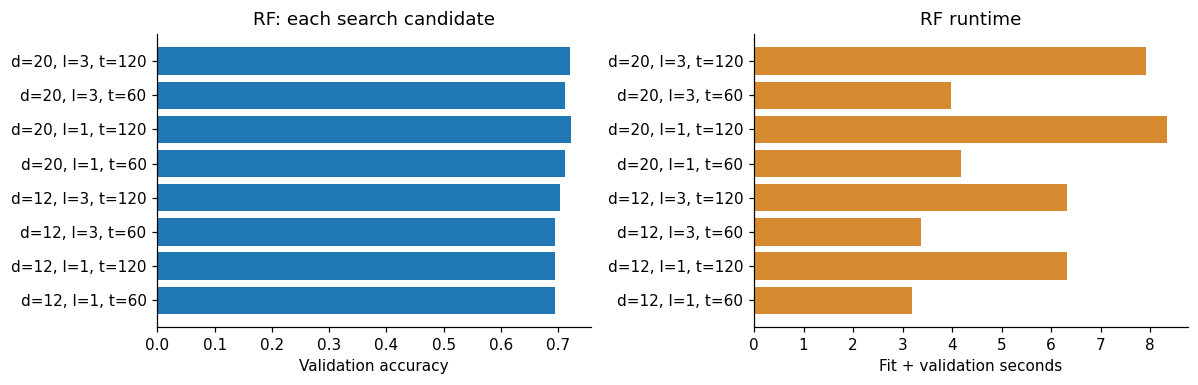

In [9]:
rf_grid = list(ParameterGrid({
    "n_estimators": [60, 120],
    "max_depth": [12, 20],
    "min_samples_leaf": [1, 3],
}))
rf_search_rows = []
for number, config in enumerate(rf_grid, start=1):
    model = RandomForestClassifier(**config, random_state=SEED, n_jobs=4)
    t0 = time.perf_counter()
    model.fit(X_dev_rf, y_dev)
    predicted = model.predict(X_val_rf)
    elapsed = time.perf_counter() - t0
    scores = evaluate_labels(y_val, predicted)
    row = {**config, **scores, "seconds": elapsed}
    rf_search_rows.append(row)
    print(f"RF {number:2d}/{len(rf_grid)}: {config}, val_acc={scores['accuracy']:.4f}, "
          f"val_macro_f1={scores['macro_f1']:.4f}, seconds={elapsed:.2f}")

rf_search_table = pd.DataFrame(rf_search_rows)
rf_selected = sorted(rf_search_rows, key=lambda r: (r["accuracy"], r["macro_f1"]), reverse=True)[0]
print("Best RF validation configuration:", rf_selected)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labels = [f"d={r['max_depth']}, l={r['min_samples_leaf']}, t={r['n_estimators']}" for r in rf_search_rows]
axes[0].barh(labels, rf_search_table["accuracy"])
axes[0].set(xlabel="Validation accuracy", title="RF: each search candidate")
axes[1].barh(labels, rf_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Fit + validation seconds", title="RF runtime")
fig.tight_layout()
fig.savefig(FIGURES / "rf_tuning.png", dpi=160)
plt.show()

### Fully connected neural network

MLP  1/8: {'dropout': 0.1, 'hidden_units': 128, 'learning_rate': 0.0005}, val_acc=0.4464, val_macro_f1=0.3971, best_epoch=8, seconds=7.10
MLP  2/8: {'dropout': 0.1, 'hidden_units': 128, 'learning_rate': 0.001}, val_acc=0.6131, val_macro_f1=0.5960, best_epoch=30, seconds=15.13
MLP  3/8: {'dropout': 0.1, 'hidden_units': 256, 'learning_rate': 0.0005}, val_acc=0.6461, val_macro_f1=0.6271, best_epoch=28, seconds=22.04
MLP  4/8: {'dropout': 0.1, 'hidden_units': 256, 'learning_rate': 0.001}, val_acc=0.6461, val_macro_f1=0.6367, best_epoch=30, seconds=21.73
MLP  5/8: {'dropout': 0.25, 'hidden_units': 128, 'learning_rate': 0.0005}, val_acc=0.6541, val_macro_f1=0.6361, best_epoch=29, seconds=15.00
MLP  6/8: {'dropout': 0.25, 'hidden_units': 128, 'learning_rate': 0.001}, val_acc=0.6581, val_macro_f1=0.6384, best_epoch=29, seconds=15.00
MLP  7/8: {'dropout': 0.25, 'hidden_units': 256, 'learning_rate': 0.0005}, val_acc=0.6242, val_macro_f1=0.6089, best_epoch=30, seconds=22.20
MLP  8/8: {'dropout': 

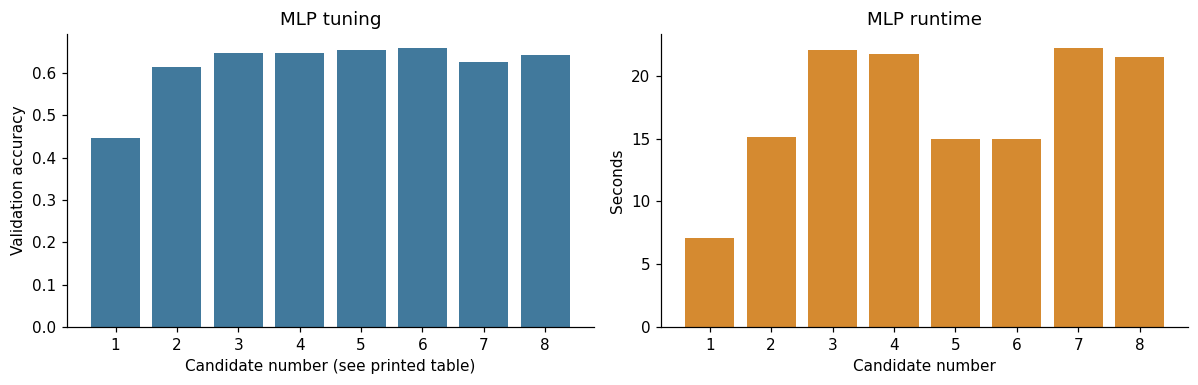

In [10]:
def search_neural_network(name, build_model, grid, max_epochs=10, patience=2,
                          reduce_lr=False):
    rows = []
    histories = []
    for number, config in enumerate(list(ParameterGrid(grid)), start=1):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_model(**config)
        stopper = keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=patience, restore_best_weights=True,
        )
        callbacks = [stopper]
        if reduce_lr:
            callbacks.append(keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=.5, patience=3, min_lr=.00001,
            ))
        t0 = time.perf_counter()
        history = model.fit(
            X_dev_img, y_dev, validation_data=(X_val_img, y_val),
            epochs=max_epochs, batch_size=128, callbacks=callbacks, verbose=0,
        )
        predicted = model.predict(X_val_img, batch_size=256, verbose=0).argmax(axis=1)
        elapsed = time.perf_counter() - t0
        scores = evaluate_labels(y_val, predicted)
        best_epoch = int(np.argmax(history.history["val_accuracy"]) + 1)
        row = {**config, **scores, "best_epoch": best_epoch,
               "epochs_ran": len(history.history["loss"]), "seconds": elapsed}
        rows.append(row)
        histories.append(history.history)
        print(f"{name} {number:2d}/{len(ParameterGrid(grid))}: {config}, "
              f"val_acc={scores['accuracy']:.4f}, val_macro_f1={scores['macro_f1']:.4f}, "
              f"best_epoch={best_epoch}, seconds={elapsed:.2f}")
        del model
    best_index = max(range(len(rows)), key=lambda i: (rows[i]["accuracy"], rows[i]["macro_f1"]))
    return pd.DataFrame(rows), best_index, histories


mlp_grid = {
    "hidden_units": [128, 256],
    "dropout": [.10, .25],
    "learning_rate": [.0005, .001],
}
mlp_search_table, mlp_best_index, mlp_search_histories = search_neural_network(
    "MLP", build_mlp, mlp_grid, max_epochs=30, patience=6, reduce_lr=True,
)
print("Best MLP validation configuration:", mlp_search_table.iloc[mlp_best_index].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
numbers = np.arange(1, len(mlp_search_table) + 1)
axes[0].bar(numbers, mlp_search_table["accuracy"], color="#41799c")
axes[0].set(xlabel="Candidate number (see printed table)", ylabel="Validation accuracy", title="MLP tuning")
axes[1].bar(numbers, mlp_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Candidate number", ylabel="Seconds", title="MLP runtime")
fig.tight_layout()
fig.savefig(FIGURES / "mlp_tuning.png", dpi=160)
plt.show()

### Convolutional neural network

CNN  1/8: {'dropout': 0.15, 'filters': 16, 'learning_rate': 0.0003}, val_acc=0.7009, val_macro_f1=0.6953, best_epoch=10, seconds=36.03
CNN  2/8: {'dropout': 0.15, 'filters': 16, 'learning_rate': 0.001}, val_acc=0.7448, val_macro_f1=0.7381, best_epoch=10, seconds=36.21
CNN  3/8: {'dropout': 0.15, 'filters': 24, 'learning_rate': 0.0003}, val_acc=0.6914, val_macro_f1=0.6831, best_epoch=10, seconds=48.53
CNN  4/8: {'dropout': 0.15, 'filters': 24, 'learning_rate': 0.001}, val_acc=0.7556, val_macro_f1=0.7442, best_epoch=9, seconds=48.22
CNN  5/8: {'dropout': 0.35, 'filters': 16, 'learning_rate': 0.0003}, val_acc=0.6897, val_macro_f1=0.6754, best_epoch=10, seconds=36.33
CNN  6/8: {'dropout': 0.35, 'filters': 16, 'learning_rate': 0.001}, val_acc=0.6819, val_macro_f1=0.6584, best_epoch=5, seconds=25.33
CNN  7/8: {'dropout': 0.35, 'filters': 24, 'learning_rate': 0.0003}, val_acc=0.6850, val_macro_f1=0.6685, best_epoch=10, seconds=48.35
CNN  8/8: {'dropout': 0.35, 'filters': 24, 'learning_rate': 

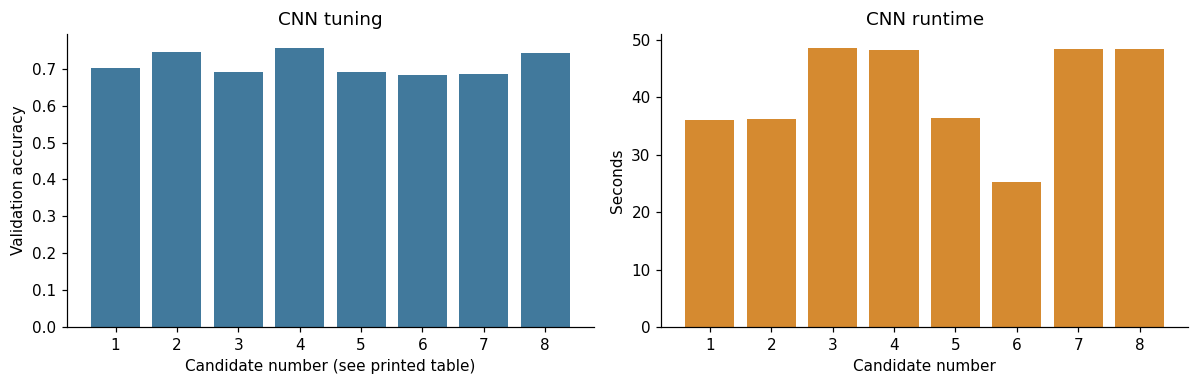

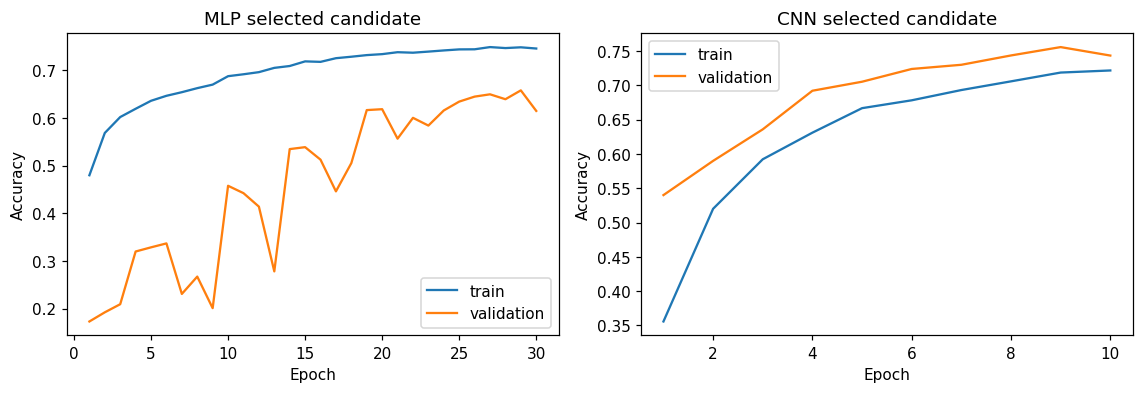

In [11]:
cnn_grid = {
    "filters": [16, 24],
    "dropout": [.15, .35],
    "learning_rate": [.0003, .001],
}
cnn_search_table, cnn_best_index, cnn_search_histories = search_neural_network(
    "CNN", build_cnn, cnn_grid,
)
print("Best CNN validation configuration:", cnn_search_table.iloc[cnn_best_index].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
numbers = np.arange(1, len(cnn_search_table) + 1)
axes[0].bar(numbers, cnn_search_table["accuracy"], color="#41799c")
axes[0].set(xlabel="Candidate number (see printed table)", ylabel="Validation accuracy", title="CNN tuning")
axes[1].bar(numbers, cnn_search_table["seconds"], color="#d58a30")
axes[1].set(xlabel="Candidate number", ylabel="Seconds", title="CNN runtime")
fig.tight_layout()
fig.savefig(FIGURES / "cnn_tuning.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
for ax, title, histories, best_index in (
    (axes[0], "MLP selected candidate", mlp_search_histories, mlp_best_index),
    (axes[1], "CNN selected candidate", cnn_search_histories, cnn_best_index),
):
    chosen = histories[best_index]
    ax.plot(np.arange(1, len(chosen["accuracy"]) + 1), chosen["accuracy"], label="train")
    ax.plot(np.arange(1, len(chosen["val_accuracy"]) + 1), chosen["val_accuracy"], label="validation")
    ax.set(xlabel="Epoch", ylabel="Accuracy", title=title)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "learning_curves.png", dpi=160)
plt.show()

## Final models

Each cell below defines its selected hyperparameters *as literals* and creates a
fresh model. It can run after Section 2 even if all Section 3 search cells are
skipped. Search tables above document why these values were selected; if you
change the data or grid, run the searches and update these values manually.
Final models fit the entire supplied 32,000-image training set. The held-out
8,000-image test set is used only now. We report test accuracy, macro F1,
weighted F1, per-class recall, training time and inference time.
The selected MLP candidate used learning-rate reductions during search; its
halving epochs are frozen below as a fixed training schedule. This reproduces
that choice on the full training set without consulting validation or test
labels in the final fit.

### Algorithm of choice from first six weeks of course: Random Forest

In [12]:
# These values are filled in after running the RF validation search.
FINAL_RF = {"max_depth": 20, "min_samples_leaf": 1, "n_estimators": 120}
final_results = {}
final_predictions = {}

rf_final = RandomForestClassifier(**FINAL_RF, random_state=SEED, n_jobs=4)
t0 = time.perf_counter()
rf_final.fit(X_train_rf, y_train)
rf_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
rf_pred = rf_final.predict(X_test_rf)
rf_predict_seconds = time.perf_counter() - t0
final_predictions["Random Forest"] = rf_pred
final_results["Random Forest"] = {
    "params": FINAL_RF, **evaluate_labels(y_test, rf_pred),
    "weighted_f1": float(f1_score(y_test, rf_pred, average="weighted", zero_division=0)),
    "fit_seconds": rf_fit_seconds, "predict_seconds": rf_predict_seconds,
    "representation_size": X_train_rf.shape[1],
}
print("Final RF:", final_results["Random Forest"])

Final RF: {'params': {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}, 'accuracy': 0.728125, 'macro_f1': 0.7120166937539213, 'weighted_f1': 0.720292818770173, 'fit_seconds': 10.609042458003387, 'predict_seconds': 0.05257145804353058, 'representation_size': 597}


### Fully connected neural network

In [13]:
# These values and the selected number of epochs are fixed after validation.
FINAL_MLP = {"hidden_units": 128, "dropout": .25, "learning_rate": .001}
FINAL_MLP_EPOCHS = 29
# The winning candidate halved its LR at these epochs during validation-stage
# ReduceLROnPlateau. Freeze that schedule as part of the selected setting, so
# full-data training does not need to inspect any held-out labels.
FINAL_MLP_LR_HALVING_EPOCHS = (10, 14, 19, 24)


def final_mlp_learning_rate(epoch, current_lr):
    halvings = sum(epoch + 1 >= milestone for milestone in FINAL_MLP_LR_HALVING_EPOCHS)
    return FINAL_MLP["learning_rate"] / (2 ** halvings)


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
mlp_final = build_mlp(**FINAL_MLP)
t0 = time.perf_counter()
mlp_final_history = mlp_final.fit(
    X_train_img, y_train, epochs=FINAL_MLP_EPOCHS, batch_size=128, verbose=0,
    callbacks=[keras.callbacks.LearningRateScheduler(final_mlp_learning_rate)],
)
mlp_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
mlp_pred = mlp_final.predict(X_test_img, batch_size=256, verbose=0).argmax(axis=1)
mlp_predict_seconds = time.perf_counter() - t0
final_predictions["MLP"] = mlp_pred
final_results["MLP"] = {
    "params": {**FINAL_MLP, "epochs": FINAL_MLP_EPOCHS,
               "lr_halving_epochs": FINAL_MLP_LR_HALVING_EPOCHS},
    **evaluate_labels(y_test, mlp_pred),
    "weighted_f1": float(f1_score(y_test, mlp_pred, average="weighted", zero_division=0)),
    "fit_seconds": mlp_fit_seconds, "predict_seconds": mlp_predict_seconds,
    "parameter_count": mlp_final.count_params(),
}
print("Final MLP:", final_results["MLP"])

Final MLP: {'params': {'hidden_units': 128, 'dropout': 0.25, 'learning_rate': 0.001, 'epochs': 29, 'lr_halving_epochs': (10, 14, 19, 24)}, 'accuracy': 0.6615, 'macro_f1': 0.642318826939638, 'weighted_f1': 0.65130963556299, 'fit_seconds': 15.038500124937855, 'predict_seconds': 0.04281370807439089, 'parameter_count': 310601}


### Convolutional neural network

In [14]:
# These values and the selected number of epochs are fixed after validation.
FINAL_CNN = {"filters": 24, "dropout": .15, "learning_rate": .001}
FINAL_CNN_EPOCHS = 9
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
cnn_final = build_cnn(**FINAL_CNN)
t0 = time.perf_counter()
cnn_final_history = cnn_final.fit(
    X_train_img, y_train, epochs=FINAL_CNN_EPOCHS, batch_size=128, verbose=0,
)
cnn_fit_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
cnn_pred = cnn_final.predict(X_test_img, batch_size=256, verbose=0).argmax(axis=1)
cnn_predict_seconds = time.perf_counter() - t0
final_predictions["CNN"] = cnn_pred
final_results["CNN"] = {
    "params": {**FINAL_CNN, "epochs": FINAL_CNN_EPOCHS},
    **evaluate_labels(y_test, cnn_pred),
    "weighted_f1": float(f1_score(y_test, cnn_pred, average="weighted", zero_division=0)),
    "fit_seconds": cnn_fit_seconds, "predict_seconds": cnn_predict_seconds,
    "parameter_count": cnn_final.count_params(),
}
print("Final CNN:", final_results["CNN"])

Final CNN: {'params': {'filters': 24, 'dropout': 0.15, 'learning_rate': 0.001, 'epochs': 9}, 'accuracy': 0.7765, 'macro_f1': 0.7691203561958792, 'weighted_f1': 0.776103098391655, 'fit_seconds': 49.10278524993919, 'predict_seconds': 0.4971702080219984, 'parameter_count': 162265}


### Side-by-side test comparison

The confusion matrices use actual classes as rows and predicted classes as
columns. Class-wise recall helps reveal weaknesses hidden by overall accuracy.
Do not use these test results to change hyperparameters.

Selected final settings:
  Random Forest: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 120}
  MLP: {'hidden_units': 128, 'dropout': 0.25, 'learning_rate': 0.001, 'epochs': 29, 'lr_halving_epochs': (10, 14, 19, 24)}
  CNN: {'filters': 24, 'dropout': 0.15, 'learning_rate': 0.001, 'epochs': 9}
Test metrics and times:
               accuracy  macro_f1  weighted_f1  fit_seconds  predict_seconds
Random Forest    0.7281    0.7120       0.7203      10.6090           0.0526
MLP              0.6615    0.6423       0.6513      15.0385           0.0428
CNN              0.7765    0.7691       0.7761      49.1028           0.4972

 Random Forest per-class precision, recall and F1
              precision    recall  f1-score   support

           0     0.8453    0.9702    0.9035       873
           1     0.9925    0.9301    0.9603       858
           2     0.8066    0.4185    0.5511       877
           3     0.8434    0.9190    0.8796       914
           4     0.6276    0.6540    0.640

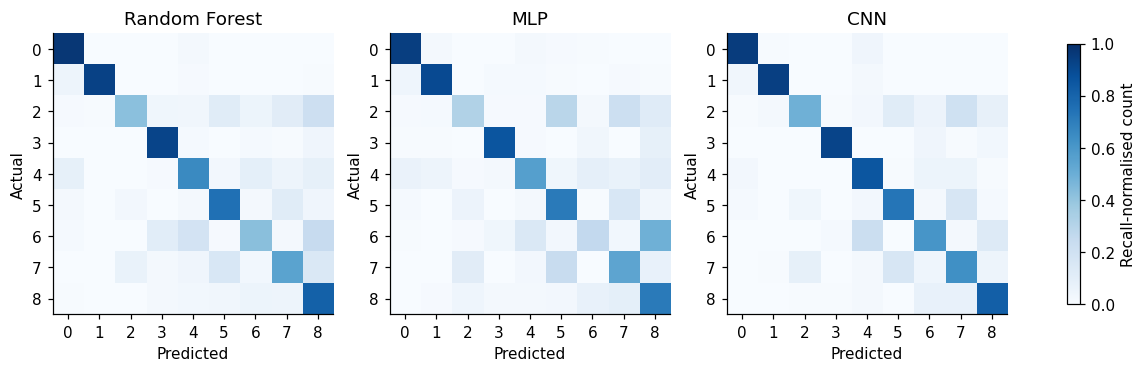

In [15]:
comparison = pd.DataFrame({
    name: {key: result[key] for key in
           ("accuracy", "macro_f1", "weighted_f1", "fit_seconds", "predict_seconds")}
    for name, result in final_results.items()
}).T
print("Selected final settings:")
for name, result in final_results.items():
    print(f"  {name}: {result['params']}")
print("Test metrics and times:")
print(comparison.to_string(float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.1))
for ax, (name, predicted) in zip(axes, final_predictions.items()):
    matrix = confusion_matrix(y_test, predicted, labels=class_ids)
    display = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(display, vmin=0, vmax=1, cmap="Blues")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual",
           xticks=np.arange(NUM_CLASSES), yticks=np.arange(NUM_CLASSES))
fig.colorbar(image, ax=axes, label="Recall-normalised count", shrink=.75)
fig.savefig(FIGURES / "test_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

for name, predicted in final_predictions.items():
    print("\n", name, "per-class precision, recall and F1")
    print(classification_report(y_test, predicted, labels=class_ids, zero_division=0, digits=4))

## AI Acknowledgement

OpenAI Codex helped interpret the provided PDF and template, inspect the local
data and existing dependencies, design and write the three scikit-learn/Keras
models, execute the experiments, verify the outputs, and draft the accompanying
report. The saved numerical results were produced by running this notebook on
the course-provided arrays. The group should review the code, claims and course
AI-use rules before submission; group identifiers and individual contributions
must be supplied by the students rather than invented here.